# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170247        # <-- your full roll number
NAME = "Aishna"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170247   Name: Aishna   Fingerprint: 20A7EC1F   Tickets: 14

Ticket_ID                                                                                 Ticket_Text
      T01                I reinstalled the student portal during the lab. I have tried several times!
      T02                              The MATLAB keeps disconnecting. The same problem occurs again.
      T03                I couldn't connect to the e-mail on my laptop. It works on another computer.
      T04 Printer was working yesterday before the assignment deadline. It works on another computer.
      T05                                                Call me on +91 98765 43210 or 0175-239-3201.
      T06                                                 I can't login and I didn't change anything.
      T07                                             The Matlab is not working. It worked yesterday.
      T08                                                               The LMS says 'Not Submitted'.
    

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:

# Q1: Preprocessing

processed = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []
for ticket_id, result in zip(df["Ticket_ID"], processed):
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

q1_table = pd.DataFrame(rows)

# Totals for additive count columns; unique tokens is corpus-wide.
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation": q1_table["Punctuation"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique tokens": len(set(t for r in processed for t in r["tokens"])),
    "Final tokens": q1_table["Final tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)
display(q1_table)

# Display actual token lists for one selected ticket
selected_id = "T01"
idx = df.index[df["Ticket_ID"] == selected_id][0]
selected = processed[idx]

print("Selected ticket:", selected_id)
print("Raw text:", df.loc[idx, "Ticket_Text"])
print("Tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])

# Non-word fragments created by word_tokenize
print("\nFinal tokens that are contraction fragments:")
print(sorted({
    t for r in processed for t in r["final"]
    if t in {"n't", "'s", "'re", "'ve", "'ll", "'d", "'m", "ca", "wo"}
}))


,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique tokens,Final tokens
0,T01,2,15,2,6,13,7
1,T02,2,11,2,4,9,5
2,T03,2,17,2,7,15,8
3,T04,2,15,2,5,14,8
4,T05,1,9,1,3,9,5
5,T06,1,11,1,4,9,6
6,T07,2,10,2,4,9,4
7,T08,1,7,2,1,7,4
8,T09,2,9,2,2,8,5
9,T10,2,14,2,5,14,7


Selected ticket: T01
Raw text: I reinstalled the student portal during the lab. I have tried several times!
Tokens: ['i', 'reinstalled', 'the', 'student', 'portal', 'during', 'the', 'lab', '.', 'i', 'have', 'tried', 'several', 'times', '!']
Punctuation tokens: ['.', '!']
Stopwords: ['i', 'the', 'during', 'the', 'i', 'have']
Final tokens: ['reinstalled', 'student', 'portal', 'lab', 'tried', 'several', 'times']

Final tokens that are contraction fragments:
['ca', "n't"]


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


# Q2: Regular expressions
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

raw_tickets = df["Ticket_Text"].tolist()
all_text = "\n".join(raw_tickets)

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![\w.])\d+(?:,\d{3})*(?:\.\d+)*(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words beginning with a vowel": r"\b[aeiouAEIOU][A-Za-z]*\b"
}

for label, pattern in patterns.items():
    print(f"\n{label}:")
    print(re.findall(pattern, all_text))

# Patterns for replacement
email_pattern = r"(?i)\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b"
url_pattern = r"(?i)\b(?:https?://|www\.)[^\s<>]+"
phone_pattern = (
    r"(?<!\w)(?:"
    r"\+91[\s-]*\d{5}[\s-]*\d{5}"
    r"|"
    r"\+91[\s-]*\d{10}"
    r"|"
    r"\d{4}[- ]\d{3}[- ]\d{4}"
    r")(?!\w)"
)

def redact(text):
    # Email first, URL second, phone third
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nRedacted tickets:")
for ticket in raw_tickets:
    print(redact(ticket))

print("\nRedacted TEST_LINES:")
for line in TEST_LINES:
    print(redact(line))

# Capitalized words that occur at sentence beginnings
sentence_initial_words = []
for text in raw_tickets:
    for sentence in sent_tokenize(text):
        match = re.search(r"\b[A-Z][a-zA-Z]*\b", sentence)
        if match and match.start() == re.search(r"\S", sentence).start():
            sentence_initial_words.append(match.group())

print("\nCapitalized words at sentence beginnings:")
print(sentence_initial_words)
print("Count:", len(sentence_initial_words))



Words longer than 5 letters:
['reinstalled', 'student', 'portal', 'during', 'several', 'MATLAB', 'disconnecting', 'problem', 'occurs', 'couldn', 'connect', 'laptop', 'another', 'computer', 'Printer', 'working', 'yesterday', 'before', 'assignment', 'deadline', 'another', 'computer', 'change', 'anything', 'Matlab', 'working', 'worked', 'yesterday', 'Submitted', 'laptop', 'working', 'yesterday', 'Please', 'stopped', 'syncing', 'during', 'several', 'couldn', 'connect', 'mobile', 'hotspot', 'changed', 'Windows', 'Projector', 'showing', 'uploading', 'urgent', 'Server', 'failed', 'during', 'Please', 'resolve']

Numbers:
['91', '98765', '43210', '0175', '239', '11', '5.30']

Capitalized words:
['I', 'I', 'The', 'MATLAB', 'The', 'I', 'It', 'Printer', 'It', 'Call', 'I', 'I', 'The', 'Matlab', 'It', 'The', 'LMS', 'Not', 'Submitted', 'The', 'Please', 'Wi', 'Fi', 'I', 'I', 'VPN', 'I', 'I', 'I', 'Windows', 'Projector', 'This', 'Server', 'Please']

Words beginning with a vowel:
['I', 'I', 'occurs', '

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:

# Q3: Custom tokenizer using ONE RegexpTokenizer pattern
from nltk.tokenize import RegexpTokenizer

token_pattern = (
    r"(?i)(?:"
    # URLs
    r"https?://[^\s<>]+|www\.[^\s<>]+"
    r"|"
    # Email addresses
    r"[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}"
    r"|"
    # Indian phone numbers in the assignment
    r"\+91[\s-]*\d{5}[\s-]*\d{5}"
    r"|\+91[\s-]*\d{10}"
    r"|\d{4}[- ]\d{3}[- ]\d{4}"
    r"|"
    # Versions, decimals, and comma-separated numbers
    r"\d+(?:\.\d+){2,}"
    r"|\d+(?:\.\d+)+"
    r"|\d{1,3}(?:,\d{3})+"
    r"|\d+"
    r"|"
    # Contractions and hyphenated words
    r"[A-Z0-9_]+(?:['’][A-Z0-9_]+)*(?:-[A-Z0-9_]+(?:['’][A-Z0-9_]+)*)*"
    r"|"
    # Keep remaining punctuation as individual tokens
    r"[^\w\s]"
    r")"
)

my_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

print("TEST_LINES results:")
for line in TEST_LINES:
    print("\nText:", line)
    print("Custom:", my_tokenize(line))
    print("NLTK:", word_tokenize(line))

print("\nTicket comparison:")
different_tickets = []

for ticket_id, text in zip(df["Ticket_ID"], raw_tickets):
    custom = my_tokenize(text)
    standard = word_tokenize(text)
    if custom != standard:
        different_tickets.append(ticket_id)
        print(f"\n{ticket_id}")
        print("Custom:", custom)
        print("word_tokenize:", standard)

print("\nNumber of tickets with different tokenization:",
      len(different_tickets), "out of", len(df))


TEST_LINES results:

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom: ['The', 'state

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:

# Q4: Stemming and lemmatization
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Chosen after observing dataset terms such as working, syncing,
# uploading, and disconnecting.
regex_stemmer = RegexpStemmer("ing$", min=5)

lemmatizer = WordNetLemmatizer()

def to_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# Unique final tokens across all tickets
unique_final = sorted(set(
    token for result in processed for token in result["final"]
))

# POS tags from NLTK
tagged_words = nltk.pos_tag(unique_final)
pos_map = dict(tagged_words)

stem_rows = []
for word in unique_final:
    pos = to_wordnet_pos(pos_map[word])

    outputs = {
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regex_stemmer.stem(word),
        "WordNet lemma": lemmatizer.lemmatize(word, pos=pos),
        "POS": pos_map[word]
    }
    stem_rows.append(outputs)

stem_table_all = pd.DataFrame(stem_rows)

# Show only words where at least two methods differ
method_cols = ["Porter", "Lancaster", "Regexp", "WordNet lemma"]
different_outputs = stem_table_all[
    stem_table_all[method_cols].nunique(axis=1) > 1
].reset_index(drop=True)

display(different_outputs)

print("\nRegexp stemmer justification:")
print("The suffix 'ing' occurs in dataset words such as working, syncing,")
print("uploading, and disconnecting. Removing it illustrates rule-based stemming.")
print("This rule is deliberately simple and may produce invalid word forms.")


,Word,Porter,Lancaster,Regexp,WordNet lemma,POS
0,another,anoth,anoth,another,another,DT
1,anything,anyth,anyth,anyth,anything,NN
2,assignment,assign,assign,assignment,assignment,NN
3,call,call,cal,call,call,VB
4,change,chang,chang,change,change,NN
5,changed,chang,chang,changed,change,VBN
6,computer,comput,comput,computer,computer,NN
7,deadline,deadlin,deadlin,deadline,deadline,VB
8,error,error,er,error,error,NN
9,failed,fail,fail,failed,fail,VBD



Regexp stemmer justification:
The suffix 'ing' occurs in dataset words such as working, syncing,
uploading, and disconnecting. Removing it illustrates rule-based stemming.
This rule is deliberately simple and may produce invalid word forms.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total tokens,Unique tokens,TTR
0,S1: All tokens,173,95,0.549133
1,S2: Without punctuation,148,92,0.621622
2,S3: Final tokens,87,66,0.758621
3,S4: Porter-stemmed S3,87,63,0.724138



Top 10 words in S1:
[('.', 22), ('the', 13), ('i', 10), ("n't", 5), ('on', 4), ('it', 4), ('during', 3), ('lab', 3), ('to', 3), ('working', 3)]

Top 10 words in S3:
[("n't", 5), ('lab', 3), ('working', 3), ('yesterday', 3), ('tried', 2), ('several', 2), ('times', 2), ('matlab', 2), ('could', 2), ('connect', 2)]


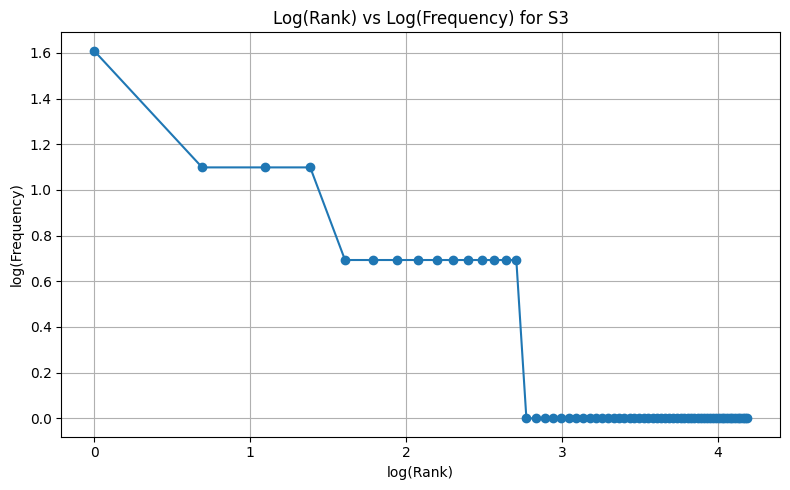


Top 5 bigrams in S1:
[(('.', 'i'), 6), (('.', 'the'), 4), (('during', 'the'), 3), (('the', 'lab'), 3), (('lab', '.'), 3)]

Top 5 bigrams in S3:
[(('lab', 'tried'), 2), (('tried', 'several'), 2), (('several', 'times'), 2), (('could', "n't"), 2), (("n't", 'connect'), 2)]


In [ ]:

# Q5: Corpus statistics
import math
import matplotlib.pyplot as plt
from nltk.util import bigrams
from collections import Counter

S1 = [t for result in processed for t in result["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for result in processed for t in result["final"]]
S4 = [porter.stem(t) for t in S3]

def corpus_stats(name, tokens):
    return {
        "Corpus": name,
        "Total tokens": len(tokens),
        "Unique tokens": len(set(tokens)),
        "TTR": len(set(tokens)) / len(tokens) if tokens else 0
    }

stats = pd.DataFrame([
    corpus_stats("S1: All tokens", S1),
    corpus_stats("S2: Without punctuation", S2),
    corpus_stats("S3: Final tokens", S3),
    corpus_stats("S4: Porter-stemmed S3", S4)
])

display(stats)

# Top 10 words in S1 and S3
print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

# Log(rank) vs log(frequency) for S3
frequencies = sorted(Counter(S3).values(), reverse=True)
ranks = list(range(1, len(frequencies) + 1))

log_ranks = [math.log(r) for r in ranks]
log_frequencies = [math.log(f) for f in frequencies]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker="o", linestyle="-")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.tight_layout()
plt.show()

# Top 5 bigrams in S1 and S3
print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*